In [2]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt

# Machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
)

df = pd.read_csv("Patient_Health_Records_Raw.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (10000, 17)


,Patient_ID,Name,Age,Gender,City,BMI,Blood_Pressure,Heart_Rate,Cholesterol_Level,Diabetic,Smoker,Medications,Last_Visit_Date,Follow_Up,Diagnosis_Code,Notes,Has_Disease
0,ID-00001,"SMITH, ALICE",250,Unknown,Boston,22kg/m2,120 over 80,83,190,Unknown,yes,NaN,Apr 15 2021,30,A00,Patient feeling fine 🙂,0
1,ID-00002,"SMITH, ALICE",-5,FEMALE,newyork,25.8,NaN,500,normal,N,No,NaN,2021-07-10,NaN,unknown,"BP high, needs recheck",unknown
2,ID-00003,John Doe,-5,NaN,Nwe Yrok,22kg/m2,120 - 80,500,190,no,Former,"aspirin,metformin",Apr 06 2021,30,B20,NaN,unknown
3,ID-00004,michael brown,80,F,New York,33.4,NaN,eighty,250,y,EX-smoker,NaN,20241113,30,NaN,Follow up soon,unknown
4,ID-00005,Jane Doe,250,male,la,30.1,120 over 80,0,normal,no,No,NaN,2025-09-27,NaN,I10,Patient feeling fine 🙂,1


In [22]:
# Dataset dimensions
print( "Rows & Column",df.shape)

# Data types
print("\nData types:")
print(df.dtypes)

# Missing values
print("\nMissing values in each column:")
print(df.isnull().sum())


Rows & Column (10000, 17)

Data types:
Patient_ID           object
Name                 object
Age                  object
Gender               object
City                 object
BMI                  object
Blood_Pressure       object
Heart_Rate           object
Cholesterol_Level    object
Diabetic             object
Smoker               object
Medications          object
Last_Visit_Date      object
Follow_Up            object
Diagnosis_Code       object
Notes                object
Has_Disease          object
dtype: object

Missing values in each column:
Patient_ID            507
Name                    0
Age                     0
Gender               1707
City                 1003
BMI                  2418
Blood_Pressure       2030
Heart_Rate              0
Cholesterol_Level    2052
Diabetic             1641
Smoker               3234
Medications          4024
Last_Visit_Date         0
Follow_Up            2524
Diagnosis_Code       1675
Notes                4024
Has_Disease          25

In [4]:
# Check the distribution of the target variable
print("Has_Disease distribution:")
print(df["Has_Disease"].value_counts(dropna=False))

# Percentage distribution
print("\nPercentage distribution:")
print(df["Has_Disease"].value_counts(normalize=True, dropna=False) * 100)

Has_Disease distribution:
Has_Disease
NaN        2520
0          2513
unknown    2506
1          2461
Name: count, dtype: int64

Percentage distribution:
Has_Disease
NaN        25.20
0          25.13
unknown    25.06
1          24.61
Name: proportion, dtype: float64


In [34]:
# Make a copy so the original raw dataframe remains unchanged
data = df.copy()
print("SHAPE before",data.shape)
print('BEFORE CLEANING',data.Has_Disease.value_counts())
# Clean the target variable
data["Has_Disease"] = pd.to_numeric(data["Has_Disease"], errors="coerce")

# Keep only rows with a valid target: 0 or 1
data = data[data["Has_Disease"].isin([0, 1])].copy()

print("Shape AFTER removing unknown/missing target rows:", data.shape)
print(data["Has_Disease"].value_counts())

SHAPE before (10000, 17)
BEFORE CLEANING Has_Disease
0          2513
unknown    2506
1          2461
Name: count, dtype: int64
Shape AFTER removing unknown/missing target rows: (4974, 17)
Has_Disease
0.0    2513
1.0    2461
Name: count, dtype: int64


In [46]:
# Convert Age to numeric.
# Values such as "twenty" become NaN.
data["Age"] = pd.to_numeric(data["Age"], errors="coerce")

# Remove unrealistic ages by replacing them with NaN.
data.loc[(data["Age"] < 0) | (data["Age"] > 120), "Age"] = np.nan
print("AGE:-",data.Age.describe())

# Clean BMI.
# First remove the text unit "kg/m2", then convert to numeric.
data["BMI"] = (
    data["BMI"]
    .astype("string")
    .str.replace("kg/m2", "", regex=False)
    .str.strip()
)
data["BMI"] = pd.to_numeric(data["BMI"], errors="coerce")
data.loc[(data["BMI"] < 10) | (data["BMI"] > 60), "BMI"] = np.nan
print("BMI:-",data.BMI.describe())

# Clean Heart Rate.
data["Heart_Rate"] = pd.to_numeric(data["Heart_Rate"], errors="coerce")
data.loc[(data["Heart_Rate"] < 40) | (data["Heart_Rate"] > 200), "Heart_Rate"] = np.nan
print("Heart_Rate:-",data.Heart_Rate.describe())

# Clean Follow_Up.
# "two weeks" is converted to 14 days.
data["Follow_Up"] = data["Follow_Up"].astype("string").str.strip().str.lower()
data["Follow_Up"] = data["Follow_Up"].replace({"two weeks": "14"})
data["Follow_Up"] = pd.to_numeric(data["Follow_Up"], errors="coerce")
data.loc[(data["Follow_Up"] < 0) | (data["Follow_Up"] > 365), "Follow_Up"] = np.nan
print("Follow_UP:-", data.Follow_Up.describe())

print("Numeric cleaning completed.")

AGE:- count    1272.000000
mean       49.137579
std        29.410935
min         0.000000
25%        23.000000
50%        50.000000
75%        75.000000
max       100.000000
Name: Age, dtype: float64
BMI:- count       3769.0
mean     23.075909
std       3.493683
min           15.0
25%           22.0
50%           22.5
75%           22.5
max           35.0
Name: BMI, dtype: Float64
Heart_Rate:- count    1282.000000
mean       85.039782
std        20.495329
min        50.000000
25%        67.000000
50%        85.000000
75%       103.000000
max       120.000000
Name: Heart_Rate, dtype: float64
Follow_UP:- count       3702.0
mean     19.212318
std       7.499601
min           14.0
25%           14.0
50%           14.0
75%           30.0
max           30.0
Name: Follow_Up, dtype: Float64
Numeric cleaning completed.


In [7]:
# Clean Blood Pressure and split it into two numeric columns.
# This handles formats like:
# 120/80, 120 - 80, and 120 over 80.

bp_text = data["Blood_Pressure"].astype("string").str.lower()

bp_text = bp_text.str.replace("over", "/", regex=False)
bp_text = bp_text.str.replace("-", "/", regex=False)
bp_text = bp_text.str.replace(" ", "", regex=False)

bp_parts = bp_text.str.extract(r"([0-9]+)[/]([0-9]+)")

data["Systolic_BP"] = pd.to_numeric(bp_parts[0], errors="coerce")
data["Diastolic_BP"] = pd.to_numeric(bp_parts[1], errors="coerce")

# Replace unrealistic blood pressure values with NaN.
data.loc[(data["Systolic_BP"] < 70) | (data["Systolic_BP"] > 250), "Systolic_BP"] = np.nan
data.loc[(data["Diastolic_BP"] < 40) | (data["Diastolic_BP"] > 150), "Diastolic_BP"] = np.nan

# We no longer need the original messy blood pressure column.
data.drop(columns=["Blood_Pressure"], inplace=True)

print(data[["Systolic_BP", "Diastolic_BP"]].head())

   Systolic_BP  Diastolic_BP
0          120            80
4          120            80
5          120            80
8          120            80
9         <NA>          <NA>


In [8]:
# Standardize Gender
data["Gender"] = data["Gender"].astype("string").str.strip().str.lower()
data["Gender"] = data["Gender"].replace({
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female",
    "unknown": np.nan
})

# Standardize City
data["City"] = data["City"].astype("string").str.strip().str.lower()
data["City"] = data["City"].replace({
    "newyork": "New York",
    "nwe yrok": "New York",
    "ny": "New York",
    "new york": "New York",
    "la": "Los Angeles",
    "los angeles": "Los Angeles",
    "chicago": "Chicago",
    "boston": "Boston"
})

# Standardize Diabetic
data["Diabetic"] = data["Diabetic"].astype("string").str.strip().str.lower()
data["Diabetic"] = data["Diabetic"].replace({
    "yes": "Yes",
    "y": "Yes",
    "no": "No",
    "n": "No",
    "unknown": np.nan
})

# Standardize Smoker
data["Smoker"] = data["Smoker"].astype("string").str.strip().str.lower()
data["Smoker"] = data["Smoker"].replace({
    "yes": "Yes",
    "no": "No",
    "former": "Former",
    "ex-smoker": "Former"
})

# Show cleaned categorical values
print("Gender values:")
print(data["Gender"].value_counts(dropna=False))

print("\nCity values:")
print(data["City"].value_counts(dropna=False))

print("\nDiabetic values:")
print(data["Diabetic"].value_counts(dropna=False))

print("\nSmoker values:")
print(data["Smoker"].value_counts(dropna=False))
# Convert pandas string columns to regular object columns for scikit-learn compatibility.
for col in ["Gender", "City", "Diabetic", "Smoker"]:
    data[col] = data[col].where(data[col].notna(), np.nan).astype(object)

Gender values:
Gender
<NA>      1688
Female    1658
Male      1628
Name: count, dtype: Int64

City values:
City
New York       1993
Chicago        1020
Los Angeles     929
<NA>            540
Boston          492
Name: count, dtype: Int64

Diabetic values:
Diabetic
No      1711
<NA>    1650
Yes     1613
Name: count, dtype: Int64

Smoker values:
Smoker
Former    1712
<NA>      1598
No         837
Yes        827
Name: count, dtype: Int64


In [9]:
# Function to count possible IQR outliers
def count_iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

numeric_check = ["Age", "BMI", "Heart_Rate", "Systolic_BP", "Diastolic_BP", "Follow_Up"]

print("Potential IQR outliers:")
for col in numeric_check:
    print(col, ":", count_iqr_outliers(data[col].dropna()))

print("Decision: obvious invalid values are converted to NaN; remaining valid extreme observations are retained rather than deleted automatically.")

Potential IQR outliers:
Age : 0
BMI : 1130
Heart_Rate : 0
Systolic_BP : 979
Diastolic_BP : 965
Follow_Up : 0
Decision: obvious invalid values are converted to NaN; remaining valid extreme observations are retained rather than deleted automatically.


In [10]:
# Select the features and target
features = [
    "Age", "Gender", "City", "BMI", "Heart_Rate",
    "Systolic_BP", "Diastolic_BP", "Cholesterol_Level",
    "Diabetic", "Smoker", "Follow_Up"
]

X = data[features].copy()

# Convert all pandas missing-value markers to regular NumPy NaN values.
X = X.astype(object).where(pd.notna(X), np.nan)

# Convert numeric columns to regular float columns.
for col in ["Age", "BMI", "Heart_Rate", "Systolic_BP", "Diastolic_BP", "Follow_Up"]:
    X[col] = pd.to_numeric(X[col], errors="coerce")

y = data["Has_Disease"].astype(int)

print("Features selected:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentages:")
print(y.value_counts(normalize=True) * 100)

Features selected:
['Age', 'Gender', 'City', 'BMI', 'Heart_Rate', 'Systolic_BP', 'Diastolic_BP', 'Cholesterol_Level', 'Diabetic', 'Smoker', 'Follow_Up']

Target distribution:
Has_Disease
0    2513
1    2461
Name: count, dtype: int64

Target percentages:
Has_Disease
0    50.522718
1    49.477282
Name: proportion, dtype: float64


In [11]:
# Check class imbalance
class_percent = y.value_counts(normalize=True) * 100

if class_percent.min() >= 40:
    print("The target classes are reasonably balanced.")
    print("No special resampling technique is needed.")
else:
    print("The target is imbalanced. Class weights may be considered.")

print(class_percent)

The target classes are reasonably balanced.
No special resampling technique is needed.
Has_Disease
0    50.522718
1    49.477282
Name: proportion, dtype: float64


In [12]:
# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training data shape: (3979, 11)
Testing data shape: (995, 11)

Training target distribution:
Has_Disease
0    0.505152
1    0.494848
Name: proportion, dtype: float64

Testing target distribution:
Has_Disease
0    0.505528
1    0.494472
Name: proportion, dtype: float64


In [13]:
# Define numerical and categorical columns
numeric_features = [
    "Age", "BMI", "Heart_Rate",
    "Systolic_BP", "Diastolic_BP", "Follow_Up"
]

categorical_features = [
    "Gender", "City", "Cholesterol_Level",
    "Diabetic", "Smoker"
]

# Numerical preprocessing:
# 1. Fill missing values with the median calculated from training data.
# 2. Standardize numerical variables.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# 1. Fill missing values with the most common category.
# 2. Convert categories into 0/1 columns.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing sections
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [14]:
# Create the three models

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        random_state=42
    ))
])


Three models are ready.


In [15]:
# Train all three models

logistic_model.fit(X_train, y_train)
decision_tree_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("All three models have been trained.")

All three models have been trained.


In [16]:
# Generate predictions on the test data

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

predictions = {}
probabilities = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]

print("Predictions generated for all models.")

Predictions generated for all models.


In [17]:
# Calculate evaluation metrics

results = []

for name in models:
    y_pred = predictions[name]
    y_prob = probabilities[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

# Sort by F1-score
results_df = results_df.sort_values("F1-Score", ascending=False).reset_index(drop=True)

print("Model comparison:")
display(results_df.round(4))

Model comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.4905,0.4863,0.5407,0.5120,0.5015
1,Logistic Regression,0.5055,0.5000,0.4228,0.4581,0.4884
2,Decision Tree,0.5065,0.5063,0.0813,0.1401,0.5131



Logistic Regression
Confusion Matrix:
[[295 208]
 [284 208]]


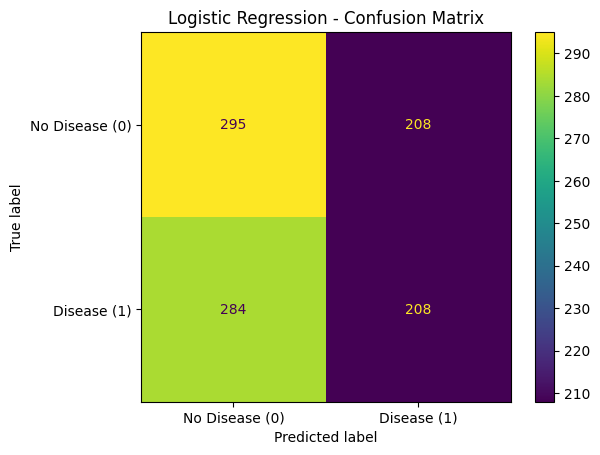


Decision Tree
Confusion Matrix:
[[464  39]
 [452  40]]


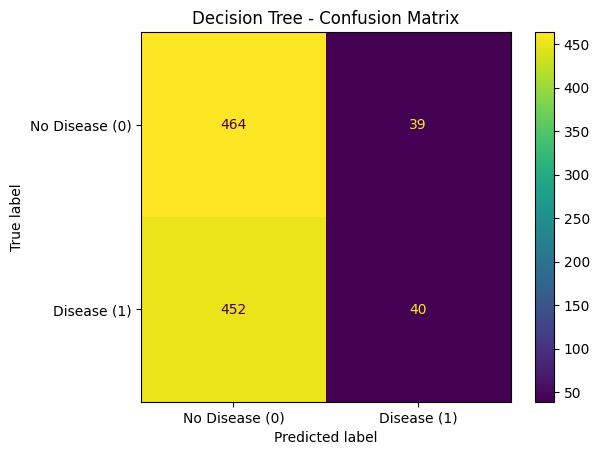


Random Forest
Confusion Matrix:
[[222 281]
 [226 266]]


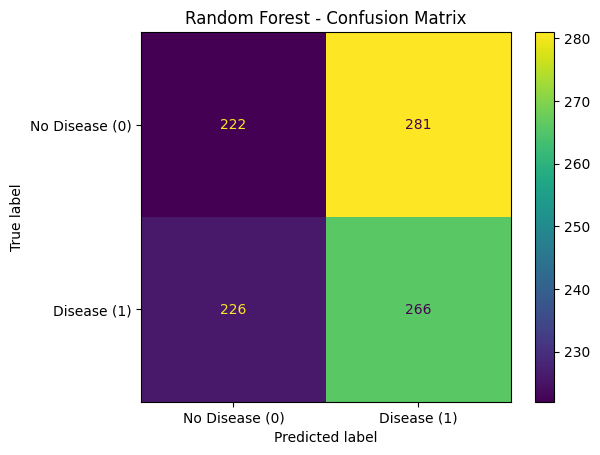

In [18]:
# Display confusion matrix for each model

for name in models:
    cm = confusion_matrix(y_test, predictions[name])

    print("\n" + "=" * 50)
    print(name)
    print("Confusion Matrix:")
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Disease (0)", "Disease (1)"]
    )
    disp.plot()
    plt.title(name + " - Confusion Matrix")
    plt.show()

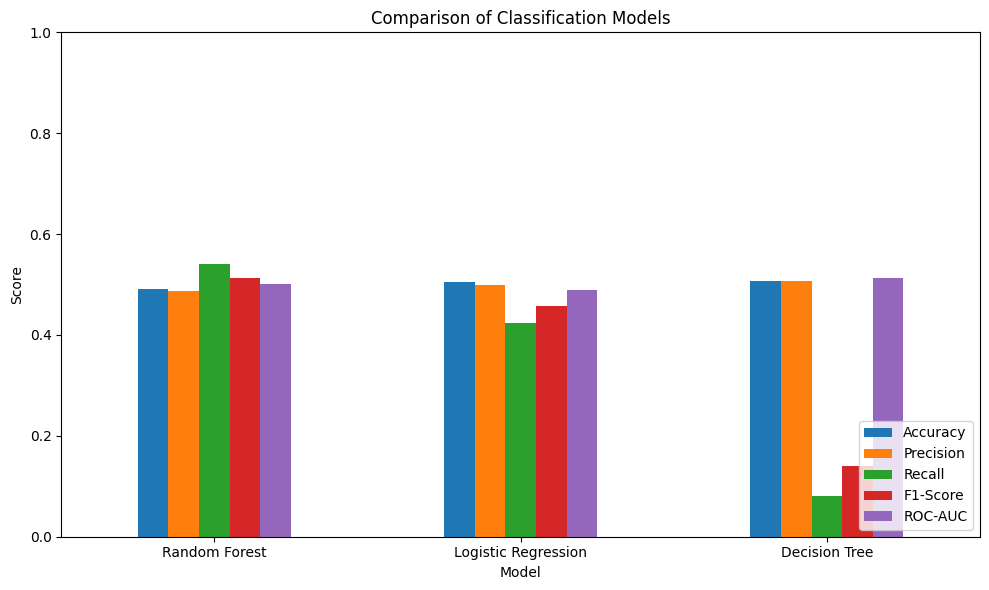

In [19]:
# Compare the main evaluation metrics visually

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(kind="bar", figsize=(10, 6))
plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()